# Jev (TypeSafe System One) — zero-shot ideology classification on `stories_10k`

Side experiment. Jev is not trained on our labels. It answers a typed question about each article
and returns a probability for Left, Centre and Right. The question is: can a calibrated judgment
model, zero-shot, match the fine-tuned BERT classifiers on the team's data?

**Method selection.** 450 labelled articles (150 per class, from the `val` stories) were scored with
four prompt designs × two state variants (article body, or title + body) in one request each.
Designs:
- `choice_simple` — "What is the political leaning?", three one-line options.
- `choice_rich` — AllSides-style framing instructions, with cues and exclusions per class.
- `score5` — a five-level left–right Score, collapsed to three classes.
- `outlet_style` — "What kind of outlet most likely published this?". This mirrors how the labels
  were actually made: they are outlet-level.

The winner, `outlet_style` with the title, was then run over the rest of the data. A per-class prior
correction was fitted on the dev set only, because every design over-predicts Centre.

Budget: hard cap $0.95 of TypeSafe credit. The dev articles are excluded from all metrics below.

## Result

Same 29,550 labelled source articles (dev excluded):

| Model | Accuracy | Macro-F1 | Recall L / C / R |
|---|---|---|---|
| **Jev zero-shot (raw)** | **47.8%** | **45.8** | 0.37 / 0.80 / 0.26 |
| Jev + dev prior correction | 46.4% | 44.9 | 0.25 / 0.70 / 0.44 |
| ChunkyBERT, fine-tuned 5 epochs | 44.3% | 40.7 | 0.49 / 0.13 / 0.71 |
| No Classifier, fine-tuned 1 epoch | 40.4% | 33.7 | 0.34 / 0.05 / 0.83 |

- **Jev, with no training on these labels, beats both fine-tuned BERT models**: +3.5 accuracy and
  +5.2 macro-F1 over ChunkyBERT.
- **Its errors run the opposite way.** Jev over-predicts Centre (80% Centre recall, only 26% for
  Right); the BERT models almost never predict Centre.
- **The prior correction did not transfer.** It helped by +2 macro-F1 under cross-validation on the
  450 dev articles but cost about 1 point on the full set. The dev set was too small to fit three
  offsets reliably, so the raw predictions are the headline.
- **Neutral summaries** (8,001 of 10,000 scored, a random sample): 94.5% are predicted Centre. That
  is the opposite of the BERT models, which called most of them Right.
- **Cost:** $0.95 total for 38,496 requests. Everything in this notebook runs from saved scores
  with no further API calls.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay
ROOT = Path("/root/ANLP/ANLP-Project"); J = ROOT / "jev"
sys.path.insert(0, str(J))
from evaluate import load, metrics, fit_prior, apply_prior
CLASSES = ["Left", "Centre", "Right"]
print(json.loads((J / "results/spend.json").read_text()))

{'input_tokens': 22617751, 'requests': 38496, 'usd': 0.9499}


## 1. Choosing the method (dev set, 450 articles)

In [2]:
import itertools
M = ["choice_simple", "choice_rich", "score5", "outlet_style"]
rows = []
for var in ("body", "title"):
    R = load(J / f"results/dev_{var}.jsonl"); y = [r["label"] for r in R]
    for m in M:
        d = metrics(y, [r[m]["p"] for r in R]); rows.append({"state": var, "method": m, **d})
dev = pd.DataFrame(rows).sort_values("macro_f1", ascending=False).round(2)
dev

,state,method,acc,macro_f1,rec_L,rec_C,rec_R
7,title,outlet_style,43.33,40.83,0.29,0.77,0.25
3,body,outlet_style,42.22,38.43,0.29,0.80,0.18
4,title,choice_simple,41.56,37.49,0.24,0.81,0.19
5,title,choice_rich,39.33,37.08,0.29,0.68,0.21
6,title,score5,39.11,36.32,0.29,0.70,0.19
1,body,choice_rich,38.67,35.78,0.29,0.69,0.18
0,body,choice_simple,40.00,34.39,0.25,0.83,0.12
2,body,score5,38.44,34.28,0.28,0.74,0.13


In [3]:
# prior correction, 2-fold cross-validated on dev so the gain is not self-fitted
out = []
for var in ("body", "title"):
    R = load(J / f"results/dev_{var}.jsonl"); y = np.array([r["label"] for r in R])
    for m in M:
        P = np.array([r[m]["p"] for r in R]); idx = np.random.default_rng(0).permutation(len(y))
        h = [idx[::2], idx[1::2]]; res = []
        for k in range(2):
            off = fit_prior(y[h[k]], P[h[k]]); res.append(metrics(y[h[1-k]], apply_prior(P[h[1-k]], off)))
        out.append({"state": var, "method": m, "cv_acc": np.mean([r["acc"] for r in res]),
                    "cv_macro_f1": np.mean([r["macro_f1"] for r in res])})
pd.DataFrame(out).sort_values("cv_macro_f1", ascending=False).round(2)

,state,method,cv_acc,cv_macro_f1
7,title,outlet_style,44.89,42.85
3,body,outlet_style,42.22,40.74
5,title,choice_rich,42.89,40.40
4,title,choice_simple,41.33,39.93
2,body,score5,40.00,38.47
6,title,score5,40.22,38.33
0,body,choice_simple,38.44,36.92
1,body,choice_rich,38.00,36.56


## 2. Full run — load scores

In [4]:
run = pd.DataFrame(load(J / "results/run_outlet_style_title.jsonl"))
run[["p_left", "p_centre", "p_right"]] = pd.DataFrame(run.outlet_style.map(lambda d: d["p"]).tolist(), index=run.index)
run["confidence"] = run.outlet_style.map(lambda d: d["confidence"])
run = run.drop(columns="outlet_style")

R = load(J / "results/dev_title.jsonl")
OFF = fit_prior([r["label"] for r in R], [r["outlet_style"]["p"] for r in R])
print("prior offsets (log, L/C/R) fitted on all 450 dev articles:", OFF.round(2))
Pc = apply_prior(run[["p_left", "p_centre", "p_right"]].values, OFF)
run[["pc_left", "pc_centre", "pc_right"]] = Pc
run["pred_raw"] = run[["p_left", "p_centre", "p_right"]].values.argmax(1)
run["pred"] = Pc.argmax(1)

lab = run[run.slot != "neutral"].copy(); neu = run[run.slot == "neutral"].copy()
lab["label"] = lab.label.astype(int)
print(f"labelled scored: {len(lab)} (of 29,550 non-dev)   neutral summaries scored: {len(neu)} of 10,000")
run.to_csv(J / "results/jev_scores.csv", index=False)

prior offsets (log, L/C/R) fitted on all 450 dev articles: [-0.7  0.   1.4]
labelled scored: 29550 (of 29,550 non-dev)   neutral summaries scored: 8001 of 10,000


## 3. Confusion matrix — labelled source articles (dev excluded)

In [5]:
y = lab.label.values
for name, pred in [("raw", lab.pred_raw.values), ("prior-corrected", lab.pred.values)]:
    print(f"{name:16} accuracy {(pred == y).mean():.4f}")
cm = confusion_matrix(y, lab.pred.values, labels=[0, 1, 2])
cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]); cm_df["total"] = cm_df.sum(1)
cm_df

raw              accuracy 0.4782
prior-corrected  accuracy 0.4643


/tmp/ipykernel_205899/2348206973.py:5: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  cm_df = pd.DataFrame(cm, index=[f"true {c}" for c in CLASSES], columns=[f"pred {c}" for c in CLASSES]); cm_df["total"] = cm_df.sum(1)


,pred Left,pred Centre,pred Right,total
true Left,2492,5358,2000,9850
true Centre,595,6913,2342,9850
true Right,313,5222,4315,9850


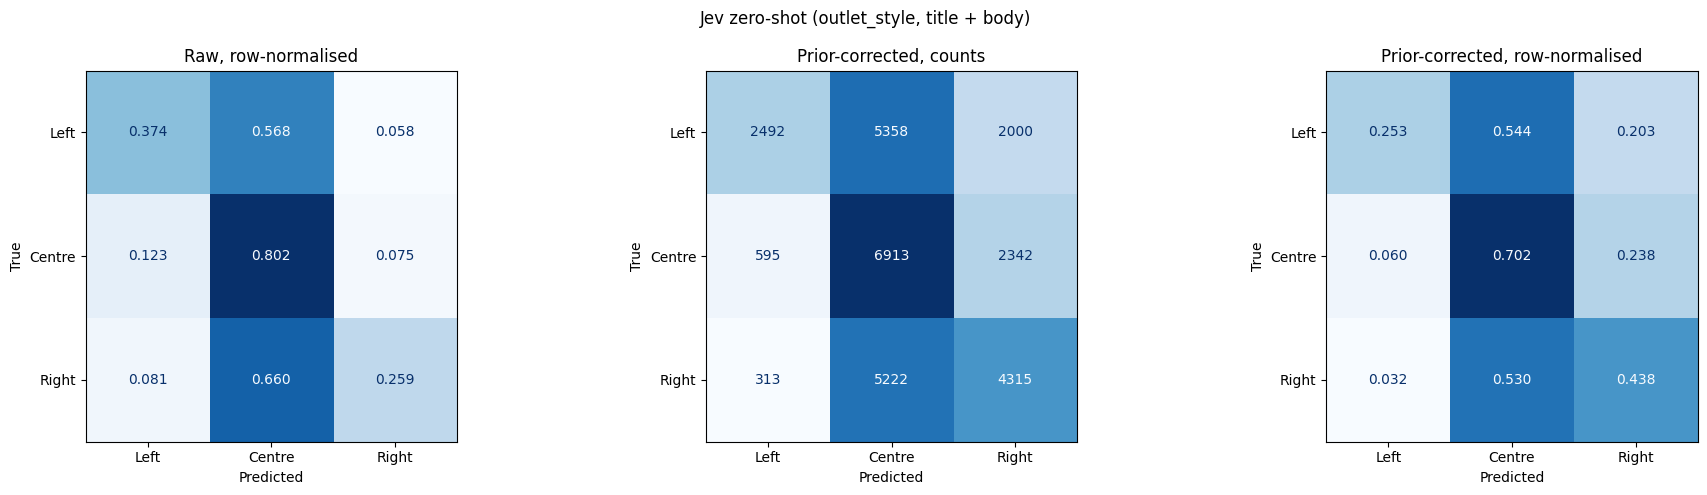

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ConfusionMatrixDisplay(confusion_matrix(y, lab.pred_raw.values, normalize="true"), display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format=".3f")
ax[0].set_title("Raw, row-normalised")
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format="d")
ax[1].set_title("Prior-corrected, counts")
ConfusionMatrixDisplay(confusion_matrix(y, lab.pred.values, normalize="true"), display_labels=CLASSES).plot(ax=ax[2], cmap="Blues", colorbar=False, values_format=".3f")
ax[2].set_title("Prior-corrected, row-normalised")
for a in ax: a.set(xlabel="Predicted", ylabel="True")
plt.suptitle("Jev zero-shot (outlet_style, title + body)"); plt.tight_layout(); plt.show()

In [7]:
print("prior-corrected:"); print(classification_report(y, lab.pred.values, target_names=CLASSES, digits=4))
print(f"AUC-ROC (OvR, macro): {roc_auc_score(y, lab[['pc_left','pc_centre','pc_right']].values, multi_class='ovr', average='macro'):.4f}")
print("\nraw:"); print(classification_report(y, lab.pred_raw.values, target_names=CLASSES, digits=4))

prior-corrected:


              precision    recall  f1-score   support

        Left     0.7329    0.2530    0.3762      9850
      Centre     0.3952    0.7018    0.5057      9850
       Right     0.4984    0.4381    0.4663      9850

    accuracy                         0.4643     29550
   macro avg     0.5422    0.4643    0.4494     29550
weighted avg     0.5422    0.4643    0.4494     29550

AUC-ROC (OvR, macro): 0.6518

raw:
              precision    recall  f1-score   support

        Left     0.6468    0.3740    0.4739      9850
      Centre     0.3950    0.8018    0.5293      9850
       Right     0.6599    0.2587    0.3717      9850

    accuracy                         0.4782     29550
   macro avg     0.5672    0.4782    0.4583     29550
weighted avg     0.5672    0.4782    0.4583     29550



## 4. Against the fine-tuned BERT models (same articles)

In [8]:
def recall(t, p): return [(p[t == c] == c).mean() for c in range(3)]
from sklearn.metrics import f1_score
rows = []
ids = set(lab.id)
for name, f in [("ChunkyBERT (5 ep)", "source_article_scores.csv"), ("No Classifier (1 ep)", "best_variant_source_scores.csv")]:
    d = pd.read_csv(ROOT / "evaluation/scores" / f)
    d["story_id"] = d.story_id.astype(str)          # align on (story_id, slot): not every file has article_id
    keep = lab[["story_id", "slot"]].assign(story_id=lab.story_id.astype(str))
    d = d.merge(keep, on=["story_id", "slot"])
    t, p = d.label.values, d.pred_id.values
    rows.append([name, len(d), (t == p).mean(), f1_score(t, p, average="macro"), *recall(t, p)])
for name, p in [("Jev raw", lab.pred_raw.values), ("Jev prior-corrected", lab.pred.values)]:
    rows.append([name, len(lab), (y == p).mean(), f1_score(y, p, average="macro"), *recall(y, p)])
pd.DataFrame(rows, columns=["model", "n", "accuracy", "macro_f1", "recall L", "recall C", "recall R"]).round(4)

,model,n,accuracy,macro_f1,recall L,recall C,recall R
0,ChunkyBERT (5 ep),29550,0.4430,0.4065,0.4868,0.1323,0.7098
1,No Classifier (1 ep),29550,0.4039,0.3374,0.3356,0.0455,0.8307
2,Jev raw,29550,0.4782,0.4583,0.3740,0.8018,0.2587
3,Jev prior-corrected,29550,0.4643,0.4494,0.2530,0.7018,0.4381


## 5. Where Jev is right and wrong

In [9]:
bands = pd.cut(lab.confidence, [0, .2, .4, .6, .8, 1.0], include_lowest=True)
(lab.assign(correct=lab.pred == lab.label).groupby(bands, observed=False)
    .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
    .assign(share=lambda t: (t.articles / len(lab)).map("{:.1%}".format), accuracy=lambda t: t.accuracy.round(4)))

,articles,accuracy,share
confidence,,,
"(-0.001, 0.2]",845,0.4213,2.9%
"(0.2, 0.4]",4244,0.4154,14.4%
"(0.4, 0.6]",4726,0.4317,16.0%
"(0.6, 0.8]",5796,0.4315,19.6%
"(0.8, 1.0]",13939,0.5065,47.2%


In [10]:
(lab.assign(correct=lab.pred == lab.label).groupby(["slot", "publisher"])
    .agg(articles=("correct", "size"), accuracy=("correct", "mean"))
    .sort_values(["slot", "accuracy"], ascending=[True, False]).round(4))

articles  accuracy
slot   publisher                    
center ap             1894    0.9461
       usatoday       1965    0.7817
       hill           5991    0.5984
left   dailykos       2233    0.5163
       hpo            2783    0.3309
       nyt            2803    0.1002
       cnn             847    0.0685
       wpo            1184    0.0667
right  breitbart      4567    0.5697
       wat            2775    0.3737
       fox            2508    0.2695

## 6. Neutral summaries (unlabelled, random sample)

In [11]:
d = pd.DataFrame({
    "mean_prob_raw":       neu[["p_left", "p_centre", "p_right"]].mean().values,
    "argmax_share_raw":    [(neu.pred_raw == i).mean() for i in range(3)],
    "argmax_share_corr":   [(neu.pred == i).mean() for i in range(3)],
}, index=CLASSES)
print(f"{len(neu)} summaries scored (random sample; the budget cap stopped the rest)")
d.round(4)

8001 summaries scored (random sample; the budget cap stopped the rest)


,mean_prob_raw,argmax_share_raw,argmax_share_corr
Left,0.1119,0.0451,0.0175
Centre,0.8355,0.9449,0.9120
Right,0.0526,0.0100,0.0705


## Notes

- **Zero-shot.** Jev never saw these labels. The only supervised step is the three-number prior
  correction, fitted on 450 held-out dev articles.
- **The labels are outlet-level**, inherited from the publisher. Asking what kind of *outlet*
  published the article beat asking about the article's *leaning*, which fits that: the
  labels measure the outlet, not the individual article.
- **Jev's bias runs opposite to BERT's.** Zero-shot, most short news excerpts read as Centre to Jev,
  so raw predictions over-use Centre. The fine-tuned BERT models almost never predict Centre.
- Per-article probabilities: `jev/results/jev_scores.csv` (raw `p_*` and corrected `pc_*`).